In [1]:
import json
from copy import deepcopy
from pathlib import Path

import numpy as np
import plotnine as gg
import polars as pl
from adjustText import adjust_text
from matplotlib.collections import PathCollection

pl.Config.set_fmt_str_lengths(900)
pl.Config.set_tbl_width_chars(900)


%load_ext autoreload
%autoreload 2

In [2]:
PROJECT_DIR = Path().resolve()
OUTPUT_DIR = PROJECT_DIR / "output"

SELECTED_TEST_RUN_TYPE = "file-stack"
SELECTED_TEST_RUN_IDS = [
    # Full 1
    # "full_2026-08-02_14-48-28_n-62-11-61_none",
    # "full_2026-08-02_14-48-29_n-62-11-60_none",
    # # Variability tests
    # "full_2026-08-02_18-11-15_n-62-11-64_variability",
    # "full_2026-08-02_18-11-15_n-62-11-65_variability",
    # "full_2026-08-02_18-11-15_n-62-11-68_variability",
    # "full_2026-08-02_18-11-55_n-62-11-66_variability",
    # Variability tests 2
    "full_2026-08-02_18-35-17_n-62-11-64_variability",
    "full_2026-08-02_18-35-18_n-62-11-68_variability",
    "full_2026-08-02_18-53-10_n-62-11-64_variability",
    "full_2026-08-02_18-53-14_n-62-11-68_variability",
]
DATASET_NAME = "Canislupus_CZM_712"

datas = []
for i, run_id in enumerate(SELECTED_TEST_RUN_IDS):
    RUN_DIR = OUTPUT_DIR / SELECTED_TEST_RUN_TYPE / run_id / DATASET_NAME
    assert RUN_DIR.exists(), f"Run directory {RUN_DIR} does not exist"

    # Load data
    for file in RUN_DIR.glob("*.json"):
        with file.open("r") as f:
            test_data = json.load(f)

        test_data["run_id"] = f"{i}::{test_data['name']}"
        datas.append(test_data)
        print(f"Loaded test data from {file.name}:")

Loaded test data from test_imagemagick_zstd_pred2_p12.json:
Loaded test data from test_tifffile_zstd_pred2_p12.json:
Loaded test data from test_libtiff_zstd_pred2_p12.json:
Loaded test data from test_imagemagick_zstd_pred2_p12.json:
Loaded test data from test_tifffile_zstd_pred2_p12.json:
Loaded test data from test_libtiff_zstd_pred2_p12.json:
Loaded test data from test_imagemagick_zstd_pred2_p12.json:
Loaded test data from test_tifffile_zstd_pred2_p12.json:
Loaded test data from test_libtiff_zstd_pred2_p12.json:
Loaded test data from test_imagemagick_zstd_pred2_p12.json:
Loaded test data from test_tifffile_zstd_pred2_p12.json:
Loaded test data from test_libtiff_zstd_pred2_p12.json:


In [3]:
from collections.abc import Mapping, Sequence


def flatten(data, prefix: str = "", sep: str = "__") -> dict:
    flattened = {}

    if isinstance(data, Mapping):
        for key, value in data.items():
            column = f"{prefix}{sep}{key}" if prefix else str(key)
            flattened.update(flatten(value, column, sep))

    elif isinstance(data, Sequence) and not isinstance(data, (str, bytes)):
        for index, value in enumerate(data):
            column = f"{prefix}[{index}]"
            flattened.update(flatten(value, column, sep))

    else:
        flattened[prefix] = data

    return flattened


rows = []
for data in datas:
    row = deepcopy(data)

    # Clean up a bit to reduce noise
    # TODO THIS IS REFACTORED
    # row.pop("array_info")
    # row["baseline_test"].pop("array_info")

    rows.append({**row, **flatten(row)})

df = pl.DataFrame(rows, strict=False)
df


name,series,subseries,paradigm,lossless,allowed_dtypes,implementation,differencing,predictor,effort,quality,tolerance,subcodec,subcodec_index,extra,id,dataset_name,dataset_path,start_wall_dt,end_wall_dt,total_wall_time_seconds,config,baseline_test,host,compress_wall_time_seconds,compress_user_time_seconds,compress_system_time_seconds,decompress_wall_time_seconds,decompress_user_time_seconds,decompress_system_time_seconds,uncompressed_size,actual_uncompressed_size,compressed_size,n_elements,compression_wall_rate,compression_user_rate,decompression_wall_rate,…,images_compressed_sizes__Canislupus_CZM_712_1147.tif,images_compressed_sizes__Canislupus_CZM_712_0325.tif,images_compressed_sizes__Canislupus_CZM_712_0894.tif,images_compressed_sizes__Canislupus_CZM_712_0974.tif,images_compressed_sizes__Canislupus_CZM_712_0132.tif,images_compressed_sizes__Canislupus_CZM_712_1502.tif,images_compressed_sizes__Canislupus_CZM_712_0786.tif,images_compressed_sizes__Canislupus_CZM_712_0966.tif,images_compressed_sizes__Canislupus_CZM_712_1242.tif,images_compressed_sizes__Canislupus_CZM_712_0853.tif,images_compressed_sizes__Canislupus_CZM_712_0679.tif,images_compressed_sizes__Canislupus_CZM_712_0896.tif,images_compressed_sizes__Canislupus_CZM_712_0646.tif,images_compressed_sizes__Canislupus_CZM_712_1012.tif,images_compressed_sizes__Canislupus_CZM_712_1389.tif,images_compressed_sizes__Canislupus_CZM_712_1444.tif,images_compressed_sizes__Canislupus_CZM_712_0422.tif,images_compressed_sizes__Canislupus_CZM_712_0114.tif,images_compressed_sizes__Canislupus_CZM_712_0221.tif,images_compressed_sizes__Canislupus_CZM_712_0432.tif,images_compressed_sizes__Canislupus_CZM_712_1430.tif,images_compressed_sizes__Canislupus_CZM_712_1217.tif,images_compressed_sizes__Canislupus_CZM_712_0410.tif,images_compressed_sizes__Canislupus_CZM_712_1266.tif,images_compressed_sizes__Canislupus_CZM_712_0612.tif,images_compressed_sizes__Canislupus_CZM_712_1064.tif,images_compressed_sizes__Canislupus_CZM_712_0332.tif,images_compressed_sizes__Canislupus_CZM_712_0526.tif,images_compressed_sizes__Canislupus_CZM_712_0706.tif,images_compressed_sizes__Canislupus_CZM_712_1132.tif,images_compressed_sizes__Canislupus_CZM_712_0621.tif,images_compressed_sizes__Canislupus_CZM_712_0902.tif,runner_extra__bulk_runner_kwargs__n_jobs,runner_extra__bulk_runner_kwargs__joblib_kwargs__prefer,config__compressor[2]__compressionargs__level,config__compressor[2]__predictor,config__comparer[1][0]
str,str,null,str,bool,list[str],str,str,i64,i64,null,null,null,null,struct[0],str,str,str,str,str,f64,struct[18],null,str,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,f64,f64,f64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,i64,i64,str
"""imagemagick_zstd_pred2_p12""","""tiff-zstd""",null,"""file_stack""",true,"[""<c32"", ""<f8"", … ""<f16""]","""imagemagick""","""horizontal""",2,12,null,null,null,null,{},"""{""name"":""imagemagick_zstd_pred2_p12"",""series"":""tiff-zstd"",""subseries"":null,""paradigm"":""file_stack"",""lossless"":true,""allowed_dtypes"":[""<c32"",""<f8"",""|b1"",""|u1"",""<u8"",""|i1"",""<i2"",""<i4"",""<i8"",""<f2"",""<f4"",""<u2"",""<u4"",""<c16"",""<c8"",""<f16""],""implementation"":""imagemagick"",""differencing"":""horizontal"",""predictor"":2,""effort"":12,""quality"":null,""tolerance"":null,""subcodec"":null,""subcodec_index"":null,""extra"":{},""compressor"":[""imagemagick.compress"",[""-compress"",""Zstd"",""-define"",""tiff:predictor=2"",""-quality"",""60""],{}],""decompressor"":[""imagemagick.decompress"",[],{}],""comparer"":[""imagemagick.compare"",[],{}]}""","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-08-02T16:49:17.626134Z""","""2026-08-02T16:51:35.681527Z""",138.0554,"{""imagemagick_zstd_pred2_p12"",""tiff-zstd"",null,""file_stack"",true,[""<c32"", ""<f8"", … ""<f16""],""imagemagick"",""horizontal"",2,12,

In [4]:
### File-stack
# Name some columns
# df = df.with_columns(pl.col("compressor").alias("serializer"))

# if "baseline_test__compress_time_seconds" in df.columns:
#     df = df.with_columns(
#         (
#             pl.col("baseline_test__compress_time_seconds")
#             / pl.col("baseline_test__compress_time_seconds").mean()
#         ).alias("baseline_test__compress_time_seconds_relative")
#     )

#     # Get std
#     compress_time_rel_std = df["baseline_test__compress_time_seconds_relative"].std()

#     # Compute error intervals
#     df = df.with_columns(
#         (pl.col("compress_time_seconds") * compress_time_rel_std).alias(
#             "compress_time_seconds_std"
#         ),
#     )


In [5]:
# # Name some columns
# df = df.with_columns(pl.col("config__serializer[0]").alias("serializer"))

# df = df.with_columns(
#     (
#         pl.col("baseline_test__compress_time_seconds")
#         / pl.col("baseline_test__compress_time_seconds").mean()
#     ).alias("baseline_test__compress_time_seconds_relative")
# )

# # Get std
# compress_time_rel_std = df["baseline_test__compress_time_seconds_relative"].std()

# # Compute error intervals
# df = df.with_columns(
#     (pl.col("compress_time_seconds") * compress_time_rel_std).alias(
#         "compress_time_seconds_std"
#     ),
# )


In [6]:
# # Baseline variability
# sns.violinplot(df.to_pandas(), x="baseline_test__compress_time_seconds_relative")

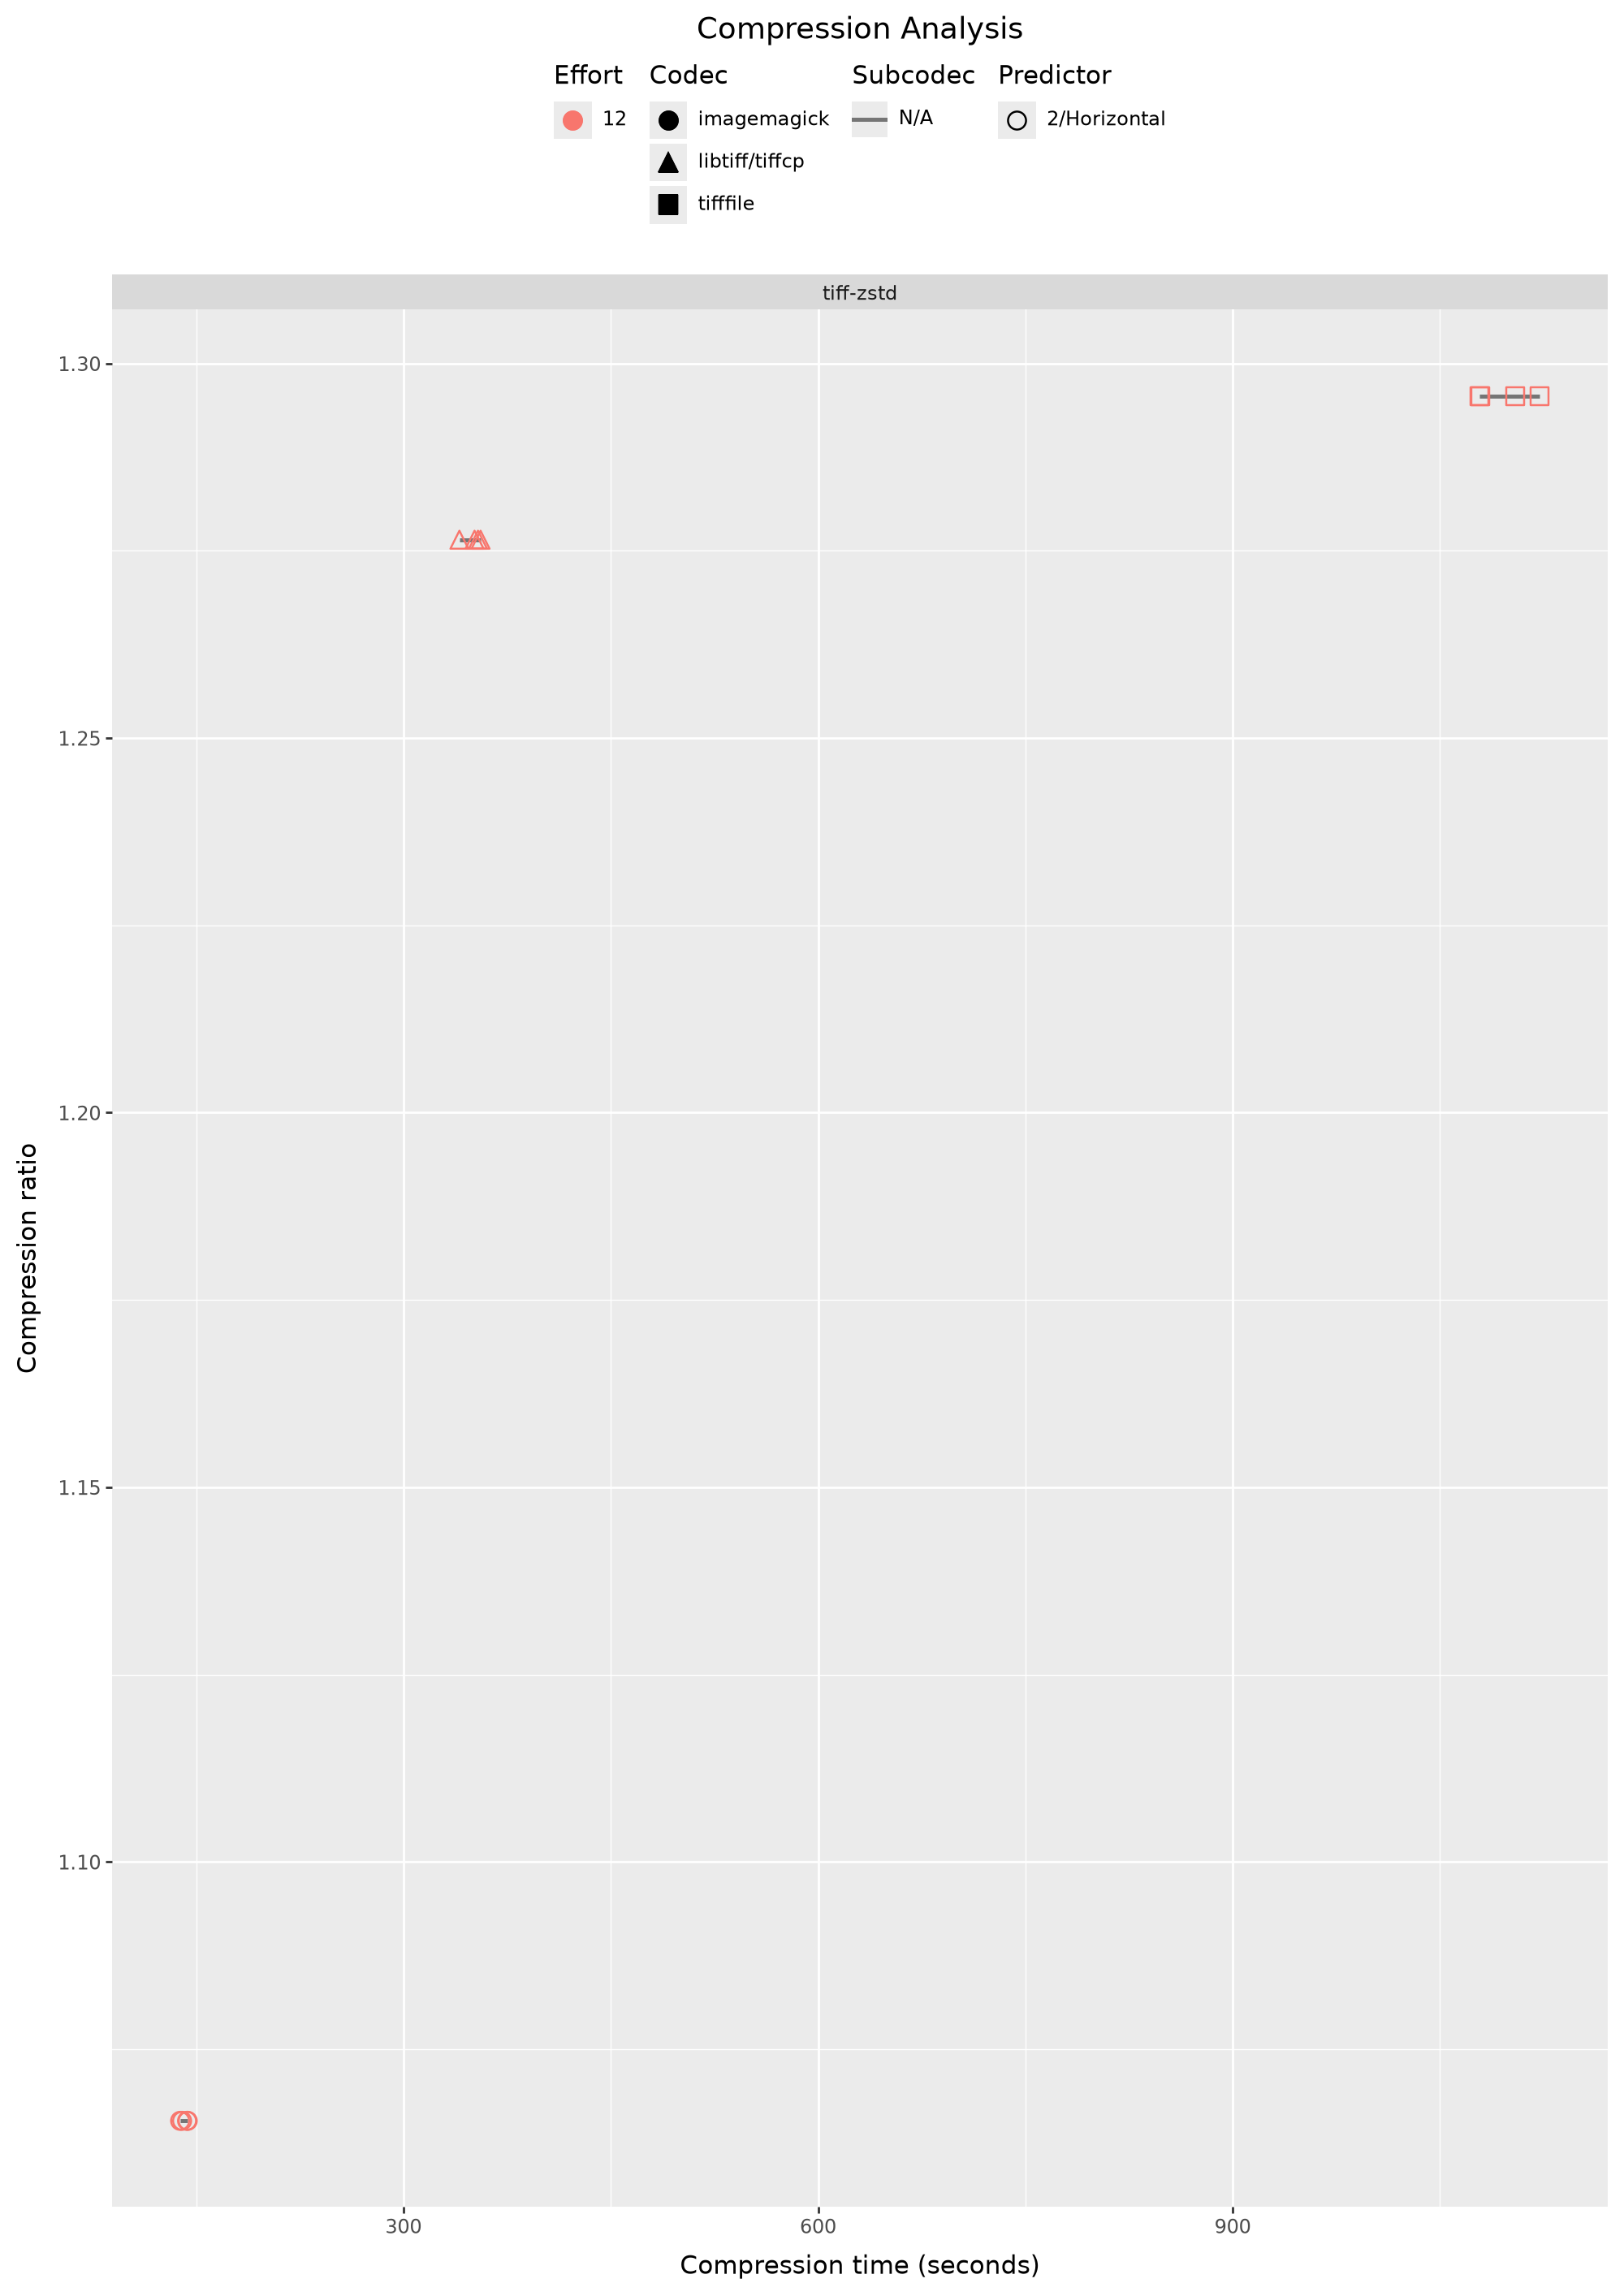

In [7]:
x_col = "compress_wall_time_seconds"
x_col = "compress_user_time_seconds"
y_col = "compression_ratio"

mash_series = {
    "tiff-jpeg-other": {
        "JPEG-2000": "tiff-jpeg2000",
        "JPEG-XR": "tiff-jpegxr",
    },
}

# source series -> combined series / displayed subcodec
series_mash_lookup = {}
subcodec_mash_lookup = {}

for combined_series, members in mash_series.items():
    for subcodec, source_series in members.items():
        if source_series in series_mash_lookup:
            raise ValueError(f"Series is mashed more than once: {source_series}")

        series_mash_lookup[source_series] = combined_series
        subcodec_mash_lookup[source_series] = subcodec

mash_mask = pl.col("series").is_in(list(series_mash_lookup))

df_for_plot = df.with_columns(
    pl.when(mash_mask)
    .then(pl.col("series").replace(series_mash_lookup))
    .otherwise(pl.col("series"))
    .alias("series"),
    # with_columns expressions see the original series column here.
    pl.when(mash_mask)
    .then(pl.col("series").replace(subcodec_mash_lookup))
    .otherwise(pl.col("subcodec"))
    .alias("subcodec"),
)

df_selected = df_for_plot.filter(
    pl.col("lossless") == True,
    pl.col("series").is_in(["tiff-baseline", "tiff-rle"]).not_(),
)

selected_cols = [
    "series",
    "implementation",
    "subcodec",
    "subcodec_index",
    "differencing",
    "predictor",
    "effort",
    x_col,
    y_col,
]

df_selected = df_selected.select(selected_cols)

groups = [
    "implementation",
    "subcodec",
    "differencing",
]

# Make group
df_selected = df_selected.with_columns(
    pl.concat_str(pl.col(groups), separator=":::", ignore_nulls=True).alias("group")
)

BILEVEL_PREDICTOR = [
    "tiff-deflate",
    "tiff-lzma",
    "tiff-lzw",
    "tiff-zstd",
]

bilevel_series = pl.col("series").is_in(BILEVEL_PREDICTOR).fill_null(False)
df_points_other = df_selected.filter(~bilevel_series)
df_points_bilevel = df_selected.filter(bilevel_series).with_columns(
    pl.col("predictor").cast(pl.String).alias("predictor_fill")
)
df_subcodec = df_selected.filter(pl.col("subcodec").is_not_null())
df_no_subcodec = df_selected.filter(pl.col("subcodec").is_null())

df_sc = df_selected.with_columns(
    pl.col("subcodec")
    .replace_strict(
        {
            "libdeflate": "A",
            "zlib": "B",
            "deflate": "A",
            "zstd": "B",
            "JPEG-2000": "A",
            "JPEG-XR": "B",
            None: "N/A",
            "none": "N/A",
        }
    )
    .cast(pl.Categorical)
)

_guide_base = {
    "direction": "vertical",
    "nrow": 4,
}
plot = (
    gg.ggplot(df_selected)
    + gg.aes(
        x=x_col,
        y=y_col,
        shape="implementation",
        color="factor(effort)",
        group="group",
    )
    + gg.geom_line(
        data=df_sc,
        mapping=gg.aes(linetype="subcodec"),
        color="black",
        alpha=0.5,
        size=1.0,
    )
    + gg.geom_point(
        data=df_points_other,
        size=4,
    )
    + gg.geom_point(
        data=df_points_bilevel,
        mapping=gg.aes(
            fill=gg.stage(
                start="predictor_fill",
                after_scale="np.where(fill == 'none', 'none', color)",
            ),
        ),
        size=4,
    )
    + gg.labs(
        title="Compression Analysis",
        x="Compression time (seconds)",
        y="Compression ratio",
    )
    # JPEG Predictor/Differencing
    + gg.geom_text(
        data=df_selected.filter(pl.col("series") == "tiff-jpeg"),
        mapping=gg.aes(label="predictor"),
        color="white",
        size=8,
    )
    + gg.scale_shape_discrete()
    + gg.facet_wrap("series", scales="free", ncol=3)
    # + gg.scale_x_continuous(expand=(0.15, 0))
    # + gg.scale_y_continuous(expand=(0.10, 0))
    + gg.scale_color_discrete(name="Effort")
    + gg.scale_linetype_manual(
        {"N/A": "solid", "A": "dashed", "B": "dotted"},
    )
    + gg.scale_fill_manual(
        values={
            "1": "black",  # Placeholder; after_scale replaces it with color
            "2": "none",
        },
        breaks=["1", "2"],
        labels=["1/None", "2/Horizontal"],
        name="Differencing",
    )
    # + gg.scale_linetype_discrete(name="Subcodec")
    + gg.theme(figure_size=(10, 10 * np.sqrt(2)), dpi=100, legend_position="top")
) + gg.guides(
    color=gg.guide_legend(title="Effort", order=1, **_guide_base),
    shape=gg.guide_legend(title="Codec", order=2, **_guide_base),
    linetype=gg.guide_legend(title="Subcodec", order=3, **_guide_base),
    fill=gg.guide_legend(title="Predictor", order=4, **_guide_base),
)
plot

In [ ]:
(
    gg.ggplot(df_selected)
    + gg.aes(
        x=x_col,
        y=y_col,
        shape="implementation",
        color="factor(effort)",
        group="group",
    )
)

In [8]:
df_selected["subcodec_index"].unique()

subcodec_index
null
null


In [9]:
df_selected["predictor"]

predictor
i64
2
2
2
2
2
…
2
2
2


In [10]:
import numpy as np
from adjustText import adjust_text
from matplotlib.collections import PathCollection

fig = plot.draw()
fig.canvas.draw()

label_values = set(agg_df["label"].to_list())

for ax in fig.axes:
    # Only the labels created by geom_text
    texts = [text for text in ax.texts if text.get_text() in label_values]

    if not texts:
        continue

    # Extract all geom_point coordinates in this particular facet
    offset_groups = [
        np.ma.asarray(collection.get_offsets())
        for collection in ax.collections
        if isinstance(collection, PathCollection) and len(collection.get_offsets())
    ]

    if not offset_groups:
        continue

    points = np.ma.vstack(offset_groups).filled(np.nan)
    points = points[np.isfinite(points).all(axis=1)]

    # Locations to which the arrows should point
    target_x = np.array([text.get_position()[0] for text in texts])
    target_y = np.array([text.get_position()[1] for text in texts])

    adjust_text(
        texts,
        x=points[:, 0],
        y=points[:, 1],
        target_x=target_x,
        target_y=target_y,
        ax=ax,
        # The point array already contains each label's anchor point
        avoid_self=False,
        ensure_inside_axes=True,
        # Label-to-label and label-to-point repulsion
        force_text=(0.2, 0.4),
        force_static=(0.5, 0.8),
        force_pull=(0.005, 0.005),
        force_explode=(0.2, 0.5),
        expand=(1.10, 1.20),
        max_move=(20, 20),
        iter_lim=1000,
        arrowprops={
            "arrowstyle": "->",
            "color": "black",
            "linewidth": 0.5,
        },
    )

fig.canvas.draw()
fig

NameError: name 'agg_df' is not defined

In [ ]:
df.filter(pl.col("series") == "tiff-jpeg")

name,series,subseries,paradigm,lossless,allowed_dtypes,implementation,differencing,predictor,effort,quality,tolerance,subcodec,subcodec_index,extra,id,dataset_name,dataset_path,start_wall_dt,end_wall_dt,total_wall_time_seconds,config,baseline_test,host,compress_wall_time_seconds,compress_user_time_seconds,compress_system_time_seconds,decompress_wall_time_seconds,decompress_user_time_seconds,decompress_system_time_seconds,uncompressed_size,actual_uncompressed_size,compressed_size,n_elements,compression_wall_rate,compression_user_rate,decompression_wall_rate,…,images_compressed_sizes__Canislupus_CZM_712_0896.tif,images_compressed_sizes__Canislupus_CZM_712_0646.tif,images_compressed_sizes__Canislupus_CZM_712_1012.tif,images_compressed_sizes__Canislupus_CZM_712_1389.tif,images_compressed_sizes__Canislupus_CZM_712_1444.tif,images_compressed_sizes__Canislupus_CZM_712_0422.tif,images_compressed_sizes__Canislupus_CZM_712_0114.tif,images_compressed_sizes__Canislupus_CZM_712_0221.tif,images_compressed_sizes__Canislupus_CZM_712_0432.tif,images_compressed_sizes__Canislupus_CZM_712_1430.tif,images_compressed_sizes__Canislupus_CZM_712_1217.tif,images_compressed_sizes__Canislupus_CZM_712_0410.tif,images_compressed_sizes__Canislupus_CZM_712_1266.tif,images_compressed_sizes__Canislupus_CZM_712_0612.tif,images_compressed_sizes__Canislupus_CZM_712_1064.tif,images_compressed_sizes__Canislupus_CZM_712_0332.tif,images_compressed_sizes__Canislupus_CZM_712_0526.tif,images_compressed_sizes__Canislupus_CZM_712_0706.tif,images_compressed_sizes__Canislupus_CZM_712_1132.tif,images_compressed_sizes__Canislupus_CZM_712_0621.tif,images_compressed_sizes__Canislupus_CZM_712_0902.tif,runner_extra__bulk_runner_kwargs__n_jobs,runner_extra__bulk_runner_kwargs__joblib_kwargs__prefer,config__compressor[2]__predictor,config__compressor[1][1],config__comparer[1][0],config__compressor[1][2],config__compressor[1][3],config__compressor[1][4],config__compressor[1][5],config__compressor[2]__compressionargs__compression,config__compressor[2]__compressionargs__compressionargs__level,config__compressor[2]__compressionargs__lossless,config__compressor[2]__compressionargs__predictor,config__compressor[1][6],config__compressor[1][7],config__compressor[2]__compressionargs__reversible
str,str,str,str,bool,list[str],str,str,i64,i64,i64,null,str,i64,struct[0],str,str,str,str,str,f64,struct[18],null,str,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,f64,f64,f64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,i64,str,str,str,str,str,str,str,i64,bool,i64,str,str,bool
"""tifffile_jpeg_lossless_pred2""","""tiff-jpeg""","""tiff-jpeg-lossless""","""file_stack""",true,"[""|u1"", ""<u2""]","""tifffile""",null,2,null,null,null,null,null,{},"""{""name"":""tifffile_jpeg_lossless_pred2"",""series"":""tiff-jpeg"",""subseries"":""tiff-jpeg-lossless"",""paradigm"":""file_stack"",""lossless"":true,""allowed_dtypes"":[""|u1"",""<u2""],""implementation"":""tifffile"",""differencing"":null,""predictor"":2,""effort"":null,""quality"":null,""tolerance"":null,""subcodec"":null,""subcodec_index"":null,""extra"":{},""compressor"":[""tifffile.compress"",[""jpeg""],{""compressionargs"":{""lossless"":true,""predictor"":2}}],""decompressor"":[""tifffile.decompress"",[],{}],""comparer"":[""tifffile.compare"",[],{}]}""","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-08-02T13:28:43.244734Z""","""2026-08-02T13:29:14.476763Z""",31.232032,"{""tifffile_jpeg_lossless_pred2"",""tiff-jpeg"",""tiff-jpeg-lossless"",""file_stack"",true,[""|u1"", ""<u2""],""tifffile"",null,2,null,null,null,null,null,{},[""tifffile.compress"", ""[jpeg]"", ""{{true,2}}""],[""tifffile.decompress"", ""[]"", ""{}""],[""tifffile.compare"", ""[]"", ""{}""]}",null,"""n-62-11-61""",20.526255,339.485008,9.779464,6.158572,84.416377,14.672833,12576198072,12576402432,8160142661,6288000000,6.1269e8,3.7045e7,2.0421e9,…,5230439,528

In [ ]:
agg_df

implementation,subcodec,differencing,series,effort,compress_wall_time_seconds,compression_ratio,label,group
str,str,str,str,i64,f64,f64,str,str
"""tifffile""",null,"""horizontal""","""tiff-zstd""",19,168.704526,1.293593,"""tifffile|horizontal""","""tifffile:::horizontal"""
"""imagemagick""",null,"""horizontal""","""tiff-zstd""",5,37.405754,1.065438,"""imagemagick|horizontal""","""imagemagick:::horizontal"""
"""tifffile""",null,"""none""","""tiff-zstd""",1,2.603331,1.064938,"""tifffile|none""","""tifffile:::none"""
"""imagemagick""",null,"""none""","""tiff-zstd""",5,37.675948,1.065438,"""imagemagick|none""","""imagemagick:::none"""
"""libtiff/tiffcp""",null,"""none""","""tiff-zstd""",5,15.671368,1.056382,"""libtiff/tiffcp|none""","""libtiff/tiffcp:::none"""
"""libtiff/tiffcp""",null,"""horizontal""","""tiff-zstd""",17,71.63684,1.274266,"""libtiff/tiffcp|horizontal""","""libtiff/tiffcp:::horizontal"""


In [ ]:
groups = [
    # "config__groupings__subcodec",
    # "config__groupings__implementation",
    "config__groupings__differencing",
]
df = df.with_columns(pl.concat_str(map(pl.col, groups)).alias("label"))

agg_df = df.group_by("label").first()
agg_df
(
    gg.ggplot(df.to_pandas().fillna("none"))
    + gg.aes(
        "compress_time_seconds",
        "compression_ratio",
        label="label",
        group=" + ".join(groups),
    )
    + gg.geom_point()
    + gg.geom_line()
    + gg.geom_text(data=agg_df, adjust_text={"arrowprops": {"arrowstyle": "->"}})
)

ColumnNotFoundError: unable to find column "config__groupings__differencing"; valid columns: ["name", "series", "subseries", "paradigm", "lossless", "allowed_dtypes", "implementation", "differencing", "predictor", "effort", "quality", "tolerance", "subcodec", "subcodec_index", "extra", "id", "dataset_name", "dataset_path", "start_wall_dt", "end_wall_dt", "total_wall_time_seconds", "config", "baseline_test", "host", "compress_wall_time_seconds", "compress_user_time_seconds", "compress_system_time_seconds", "decompress_wall_time_seconds", "decompress_user_time_seconds", "decompress_system_time_seconds", "uncompressed_size", "actual_uncompressed_size", "compressed_size", "n_elements", "compression_wall_rate", "compression_user_rate", "decompression_wall_rate", "decompression_user_rate", "bitrate_uncompressed", "bitrate_compressed", "compression_ratio", "space_saving", "was_actually_lossless", "images_input_sizes", "images_uncompressed_sizes", "images_compressed_sizes", "runner_extra", "ru

In [ ]:
df

name,id,series,vary_var,vary_value,groupings,dataset_name,dataset_path,start_dt,end_dt,total_time_seconds,config,baseline_test,host,compress_time_seconds,nbytes,nbytes_stored,npixels,bitrate,bitrate_compressed,compression_ratio,space_saving,lossless,extra,groupings__implementation,groupings__differencing,groupings__predictor,groupings__effort,groupings__subcodec,groupings__subcodec_index,config__name,config__series,config__vary_var,config__vary_value,config__groupings__implementation,config__groupings__differencing,config__groupings__predictor,config__groupings__effort,config__groupings__subcodec,config__groupings__subcodec_index,config__is_lossless,config__allowed_dtypes[0],config__allowed_dtypes[1],config__allowed_dtypes[2],config__allowed_dtypes[3],config__allowed_dtypes[4],config__allowed_dtypes[5],config__allowed_dtypes[6],config__allowed_dtypes[7],config__allowed_dtypes[8],extra__n_jobs,label
str,str,str,str,i64,struct[6],str,str,str,str,f64,struct[8],null,str,f64,i64,i64,i64,f64,f64,f64,f64,bool,struct[1],str,str,i64,i64,str,i64,str,str,str,i64,str,str,i64,i64,str,i64,bool,str,str,str,str,str,str,str,str,str,i64,str
"""libtiff_deflate_pred2_s1_p1""","""{""name"":""libtiff_deflate_pred2_s1_p1"",""series"":""tiff-deflate"",""vary_var"":""effort"",""vary_value"":1,""groupings"":{""implementation"":""libtiff/tiffcp"",""differencing"":""horizontal"",""predictor"":2,""effort"":1,""subcodec"":""libdeflate"",""subcodec_index"":1},""is_lossless"":true,""allowed_dtypes"":[""|u1"",""|i1"",""<u2"",""<u8"",""<i4"",""|b1"",""<i2"",""<u4"",""<i8""],""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""zip:2:s1:p1""],{}]}""","""tiff-deflate""","""effort""",1,"{""libtiff/tiffcp"",""horizontal"",2,1,""libdeflate"",1}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T16:52:21.358778Z""","""2026-07-29T16:52:40.691455Z""",19.332686,"{""libtiff_deflate_pred2_s1_p1"",""tiff-deflate"",""effort"",1,{""libtiff/tiffcp"",""horizontal"",2,1,""libdeflate"",1},true,[""|u1"", ""|i1"", … ""<i8""],{}}",null,"""n-62-12-19""",17.758926,12576198072,9857990032,6288000000,16.000252,12.541972,1.275737,0.216139,true,{16},"""libtiff/tiffcp""","""horizontal""",2,1,"""libdeflate""",1,"""libtiff_deflate_pred2_s1_p1""","""tiff-deflate""","""effort""",1,"""libtiff/tiffcp""","""horizontal""",2,1,"""libdeflate""",1,true,"""|u1""","""|i1""","""<u2""","""<u8""","""<i4""","""|b1""","""<i2""","""<u4""","""<i8""",16,"""horizontal"""
"""libtiff_deflate_pred2_s0_p6""","""{""name"":""libtiff_deflate_pred2_s0_p6"",""series"":""tiff-deflate"",""vary_var"":""effort"",""vary_value"":6,""groupings"":{""implementation"":""libtiff/tiffcp"",""differencing"":""horizontal"",""predictor"":2,""effort"":6,""subcodec"":""zlib"",""subcodec_index"":0},""is_lossless"":true,""allowed_dtypes"":[""|u1"",""|i1"",""<u2"",""<u8"",""<i4"",""|b1"",""<i2"",""<u4"",""<i8""],""extra"":{},""compressor"":[""libtiff.compress"",[""-c"",""zip:2:s0:p6""],{}]}""","""tiff-deflate""","""effort""",6,"{""libtiff/tiffcp"",""horizontal"",2,6,""zlib"",0}","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-07-29T16:56:20.031915Z""","""2026-07-29T16:56:52.019314Z""",31.987404,"{""libtiff_deflate_pred2_s0_p6"",""tiff-deflate"",""effort"",6,{""libtiff/tiffcp"",""horizontal"",2,6,""zlib"",0},true,[""|u1"", ""|i1"", … ""<i8""],{}}",null,"""n-62-12-19""",30.38136,12576198072,10053970018,6288000000,16.000252,12.79131,1.250869,0.200556,true,{16},"""libtiff/tiffcp""","""horizontal""",2,6,"""zlib""",0,"""libtiff_deflate_pred2_s0_p6""","""tiff-deflate""","""effort""",6,"""libtiff/tiffcp""","""horizontal""",2,6,"""zlib""",0,true,"""|u1""","""|i1""","""<u2""","""<u8""","""<i4""","""|b1""","""<i2""","""<u4""","""<i8""",16,"""horizontal"""
"""libtiff_deflate_pred1_s1_p2""","""{""name"":""libtiff_deflate_pred1_s1_p2"",""series"":""tiff-deflate"",""vary_

In [ ]:
(
    gg.ggplot(df)
    + gg.aes(
        "compress_time_seconds",
        "compression_ratio",
        shape="serializer",
        color="factor(vary_value)",
        group="series",
    )
    + gg.geom_point()
    + gg.geom_line()
    + gg.aes(
        xmin="compress_time_seconds-compress_time_seconds_std",
        xmax="compress_time_seconds+compress_time_seconds_std",
    )
    + gg.geom_errorbarh(height=0.02)
    + gg.labs(
        title="Compression Analysis",
        x="Compression time (seconds)",
        y="Compression ratio",
    )
    + gg.scale_shape_discrete(name="Codec")
    + gg.scale_color_discrete(name="Effort")
    # + gg.theme_xkcd()
)

PlotnineError: "Could not evaluate the 'shape' mapping: 'serializer' (original error: name 'serializer' is not defined)"